<a href="https://colab.research.google.com/github/Siva1212-genious/ML-Algorithms---ScikitLearn/blob/main/KNN_With_K_Means_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

iris_data =sns.load_dataset('iris')

In [2]:
iris_data

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


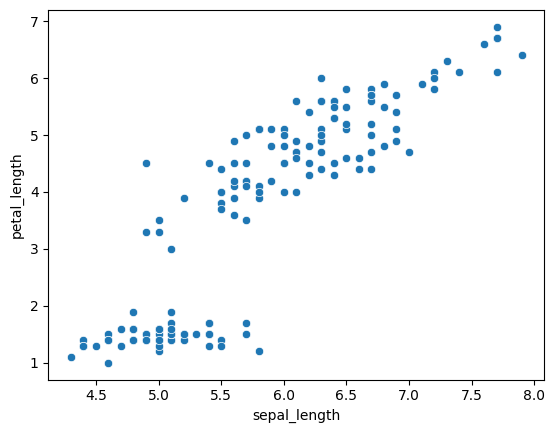

In [3]:
sns.scatterplot(data=iris_data, x='sepal_length', y='petal_length')
plt.show()

In [4]:
numeric_cols = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

In [5]:
numeric_cols

['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

In [6]:
x = iris_data[numeric_cols]

In [7]:
x

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [8]:
from sklearn.cluster import KMeans

Kmeans = KMeans(n_clusters = 2, max_iter=20, random_state=42)

Kmeans.fit(x)

KMeans(max_iter=20, n_clusters=2, random_state=42)

In [9]:
Kmeans.cluster_centers_

array([[6.30103093, 2.88659794, 4.95876289, 1.69587629],
       [5.00566038, 3.36981132, 1.56037736, 0.29056604]])

In [10]:
Kmeans.inertia_

152.34795176035797

In [11]:
Kmeans.labels_

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=int32)

In [12]:
#Now, lets create a good loop that calculates the no of features that helps to reduce the inertia_ to find the best clusters

In [13]:
inertia = []
test_range = range(1,15)

for cluster in test_range:
  k_mean = KMeans(n_clusters = cluster, max_iter = 200, random_state=42)

  k_mean.fit(x)

  inertia.append(k_mean.inertia_)
  print(cluster, k_mean.inertia_)

1 681.3705999999996
2 152.34795176035797
3 78.85566582597727
4 57.350880212954756
5 46.47223015873018
6 39.066035353535376
7 34.305815295815314
8 30.476222943722966
9 29.906246659137977
10 28.545297810033116
11 26.505681549101062
12 25.85703673287497
13 23.417720142602498
14 22.24401017528224


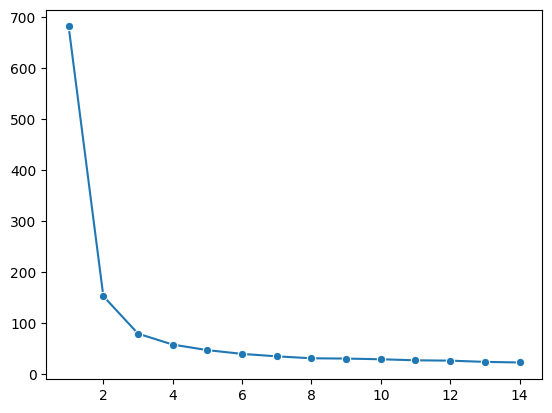

In [14]:
sns.lineplot(x=list(test_range), y=inertia, marker='o')
plt.show()

In [15]:
#Here we can see the best no_of_clusters at 3, we can notice that after 3, it is very minimum change.
#So, we can put the n_clusters = 3.

In [16]:
#Now we can fit_predict() and we can attach this to our dataset and we can use this info for using in supervised models

In [17]:
kmean = KMeans(n_clusters = 3, max_iter = 200, random_state = 42)

cluster_assignment = kmean.fit_predict(x)

iris_data['New_cluster_data'] = cluster_assignment

In [18]:
iris_data.tail(30)

,sepal_length,sepal_width,petal_length,petal_width,species,New_cluster_data
120,6.9,3.2,5.7,2.3,virginica,0
121,5.6,2.8,4.9,2.0,virginica,2
122,7.7,2.8,6.7,2.0,virginica,0
123,6.3,2.7,4.9,1.8,virginica,2
124,6.7,3.3,5.7,2.1,virginica,0
125,7.2,3.2,6.0,1.8,virginica,0
126,6.2,2.8,4.8,1.8,virginica,2
127,6.1,3.0,4.9,1.8,virginica,2
128,6.4,2.8,5.6,2.1,virginica,0
129,7.2,3.0,5.8,1.6,virginica,0


In [19]:
kmean.cluster_centers_

array([[6.85384615, 3.07692308, 5.71538462, 2.05384615],
       [5.006     , 3.428     , 1.462     , 0.246     ],
       [5.88360656, 2.74098361, 4.38852459, 1.43442623]])

In [20]:
kmean.labels_

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 2, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2, 0, 0, 0, 0, 2, 0, 0, 0,
       0, 0, 0, 2, 2, 0, 0, 0, 0, 2, 0, 2, 0, 2, 0, 0, 2, 2, 0, 0, 0, 0,
       0, 2, 0, 0, 0, 0, 2, 0, 0, 0, 2, 0, 0, 0, 2, 0, 0, 2], dtype=int32)

In [21]:
iris_data['cluster'] = kmean.labels_

cluster_profiles = iris_data.groupby('cluster').mean(numeric_only = True)
print(cluster_profiles)

         sepal_length  sepal_width  petal_length  petal_width  \
cluster                                                         
0            6.853846     3.076923      5.715385     2.053846   
1            5.006000     3.428000      1.462000     0.246000   
2            5.883607     2.740984      4.388525     1.434426   

         New_cluster_data  
cluster                    
0                     0.0  
1                     1.0  
2                     2.0  


In [22]:
kmean.inertia_

78.85566582597727

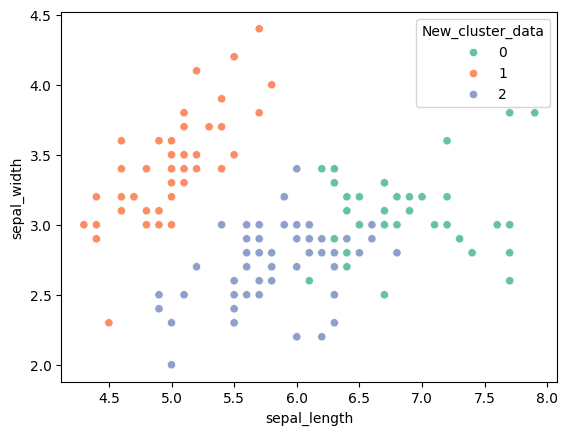

<Axes: xlabel='sepal_length', ylabel='sepal_width'>

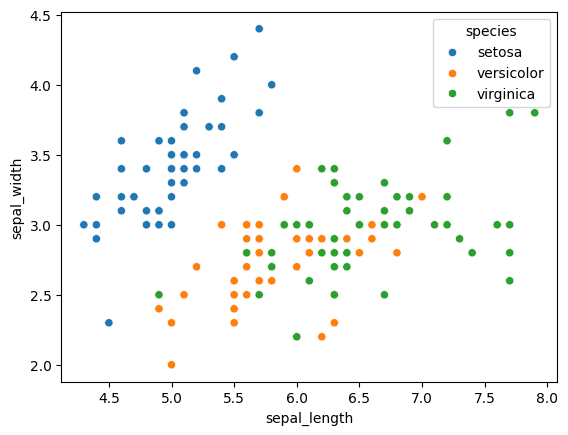

In [23]:
sns.scatterplot(data = iris_data, x = 'sepal_length', y= 'sepal_width', hue = 'New_cluster_data', palette="Set2")
plt.show()
sns.scatterplot(data = iris_data, x='sepal_length', y='sepal_width', hue='species')

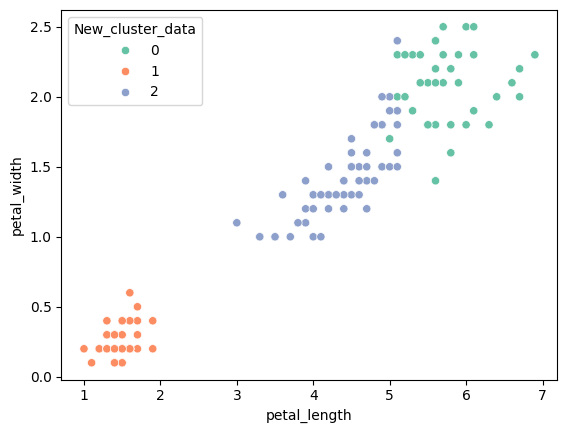

<Axes: xlabel='petal_length', ylabel='petal_width'>

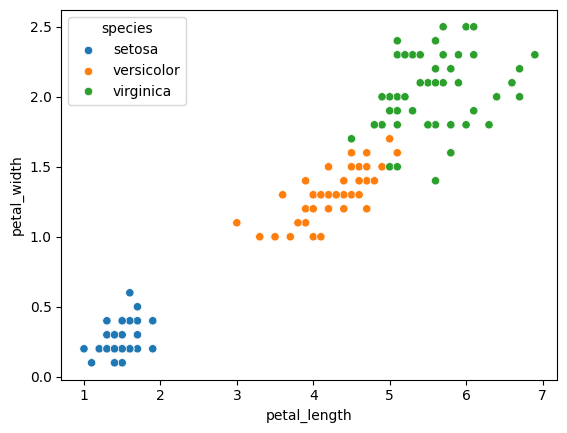

In [24]:
sns.scatterplot(data = iris_data, x = 'petal_length', y= 'petal_width', hue = 'New_cluster_data', palette="Set2")
plt.show()
sns.scatterplot(data = iris_data, x='petal_length', y='petal_width', hue='species')

In [ ]:
# Now lets perform KNN model and will predict on this iris dataset by putting New_clustered_column as target

In [30]:
iris_data

,sepal_length,sepal_width,petal_length,petal_width,species,New_cluster_data,cluster
0,5.1,3.5,1.4,0.2,setosa,1,1
1,4.9,3.0,1.4,0.2,setosa,1,1
2,4.7,3.2,1.3,0.2,setosa,1,1
3,4.6,3.1,1.5,0.2,setosa,1,1
4,5.0,3.6,1.4,0.2,setosa,1,1
...,...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica,0,0
146,6.3,2.5,5.0,1.9,virginica,2,2
147,6.5,3.0,5.2,2.0,virginica,0,0
148,6.2,3.4,5.4,2.3,virginica,0,0


In [35]:
import numpy as np

numeric_cols = iris_data.select_dtypes(include = np.number).columns.tolist()
categorical_cols = iris_data.select_dtypes(include = 'object').columns.tolist()

In [36]:
input_columns = numeric_cols[0:-2]

input_columns

['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

In [37]:
target_column = numeric_cols[-2]
target_column

'New_cluster_data'

In [38]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

iris_data[input_columns] = scaler.fit_transform(iris_data[input_columns])

iris_data

,sepal_length,sepal_width,petal_length,petal_width,species,New_cluster_data,cluster
0,-0.900681,1.019004,-1.340227,-1.315444,setosa,1,1
1,-1.143017,-0.131979,-1.340227,-1.315444,setosa,1,1
2,-1.385353,0.328414,-1.397064,-1.315444,setosa,1,1
3,-1.506521,0.098217,-1.283389,-1.315444,setosa,1,1
4,-1.021849,1.249201,-1.340227,-1.315444,setosa,1,1
...,...,...,...,...,...,...,...
145,1.038005,-0.131979,0.819596,1.448832,virginica,0,0
146,0.553333,-1.282963,0.705921,0.922303,virginica,2,2
147,0.795669,-0.131979,0.819596,1.053935,virginica,0,0
148,0.432165,0.788808,0.933271,1.448832,virginica,0,0


In [40]:
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

encoder = OneHotEncoder()

encoded_data = encoder.fit(iris_data[categorical_cols])

encoded_cols = list(encoder.get_feature_names_out(categorical_cols))

iris_data[encoded_cols] = encoder.transform(iris_data[categorical_cols])

In [41]:
iris_data

,sepal_length,sepal_width,petal_length,petal_width,species,New_cluster_data,cluster,species_setosa,species_versicolor,species_virginica
0,-0.900681,1.019004,-1.340227,-1.315444,setosa,1,1,1.0,0.0,0.0
1,-1.143017,-0.131979,-1.340227,-1.315444,setosa,1,1,1.0,0.0,0.0
2,-1.385353,0.328414,-1.397064,-1.315444,setosa,1,1,1.0,0.0,0.0
3,-1.506521,0.098217,-1.283389,-1.315444,setosa,1,1,1.0,0.0,0.0
4,-1.021849,1.249201,-1.340227,-1.315444,setosa,1,1,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...
145,1.038005,-0.131979,0.819596,1.448832,virginica,0,0,0.0,0.0,1.0
146,0.553333,-1.282963,0.705921,0.922303,virginica,2,2,0.0,0.0,1.0
147,0.795669,-0.131979,0.819596,1.053935,virginica,0,0,0.0,0.0,1.0
148,0.432165,0.788808,0.933271,1.448832,virginica,0,0,0.0,0.0,1.0


In [42]:
X = iris_data[input_columns]
Y= iris_data[encoded_cols]

X,Y

(     sepal_length  sepal_width  petal_length  petal_width
 0       -0.900681     1.019004     -1.340227    -1.315444
 1       -1.143017    -0.131979     -1.340227    -1.315444
 2       -1.385353     0.328414     -1.397064    -1.315444
 3       -1.506521     0.098217     -1.283389    -1.315444
 4       -1.021849     1.249201     -1.340227    -1.315444
 ..            ...          ...           ...          ...
 145      1.038005    -0.131979      0.819596     1.448832
 146      0.553333    -1.282963      0.705921     0.922303
 147      0.795669    -0.131979      0.819596     1.053935
 148      0.432165     0.788808      0.933271     1.448832
 149      0.068662    -0.131979      0.762758     0.790671
 
 [150 rows x 4 columns],
      species_setosa  species_versicolor  species_virginica
 0               1.0                 0.0                0.0
 1               1.0                 0.0                0.0
 2               1.0                 0.0                0.0
 3               1.0     

In [43]:
from sklearn.model_selection import train_test_split

X_train,X_test, Y_train,Y_test = train_test_split(X,Y, test_size=0.2, random_state=42)

In [48]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors = 4)

knn.fit(X_train, Y_train)

predictions = knn.predict(X_train)

In [49]:
predictions

array([[1., 0., 0.],
       [1., 0., 0.],
       [0., 1., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [0., 0., 1.],
       [0., 1., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [0., 0., 1.],
       [0., 1., 0.],
       [0., 1., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 0.],
       [0., 0., 1.],
       [0., 1., 0.],
       [0., 0., 1.],
       [0., 1., 0.],
       [0., 0., 1.],
       [0., 1., 0.],
       [1., 0., 0.],
       [0., 0., 1.],
       [0., 1., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [0., 1., 0.],
       [1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.],
       [1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.],
       [1., 0., 0.],
       [0., 0., 1.],
       [0., 0., 1.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 0., 1.],
       [0., 1

In [52]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(Y_train, predictions)

accuracy*100

93.33333333333333

In [53]:
test_pred = knn.predict(X_test)

test_accuracy = accuracy_score(Y_test, test_pred)

test_accuracy*100

100.0

In [55]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(Y_test, test_pred)

cm

array([[10,  0,  0],
       [ 0,  9,  0],
       [ 0,  0, 11]])